# TP N° 1 — Análisis Exploratorio de Datos (EDA): churn en una plataforma de streaming

Dataset: *Netflix-Style Synthetic Dataset* (Kaggle). 6 tablas relacionadas: usuarios, catálogo, historial de visualización, recomendaciones, reseñas y búsquedas.

Objetivo: entender qué distingue a los usuarios que abandonan el servicio (**churn**, `is_active = False`) de los que siguen activos, planteando hipótesis y contrastándolas con los datos.

Librerías

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Carga de datos

In [2]:
users = pd.read_csv('data/users.csv')
movies = pd.read_csv('data/movies.csv')
watch = pd.read_csv('data/watch_history.csv')
recs = pd.read_csv('data/recommendation_logs.csv')
reviews = pd.read_csv('data/reviews.csv')
search = pd.read_csv('data/search_logs.csv')

print('users: ', users.shape)
print('movies: ', movies.shape)
print('watch_history: ', watch.shape)
print('recommendation_logs: ', recs.shape)
print('reviews: ', reviews.shape)
print('search_logs: ', search.shape)

users:  (10300, 16)
movies:  (1040, 18)
watch_history:  (105000, 12)
recommendation_logs:  (52000, 11)
reviews:  (15450, 12)
search_logs:  (26500, 11)


Exploración inicial (tabla principal: users)

In [5]:
users.sample(7)

,user_id,email,first_name,last_name,age,gender,country,state_province,city,subscription_plan,subscription_start_date,is_active,monthly_spend,primary_device,household_size,created_at
841,user_00842,perry77@example.net,Kristen,Cole,NaN,Female,Canada,New Brunswick,Barrettshire,Premium,2022-08-10,True,15.43,Gaming Console,4.0,2025-06-13 16:54:45.303567
7618,user_07619,barrettwendy@example.net,John,Faulkner,40.0,Female,Canada,Nova Scotia,Stephenstad,Standard,2024-07-03,True,17.25,Laptop,1.0,2023-04-27 09:14:14.414660
4312,user_04313,josephwarren@example.com,Keith,Smith,27.0,Female,USA,Arizona,Vasquezhaven,Standard,2025-07-18,True,29.10,Laptop,4.0,2023-05-23 18:38:53.427269
771,user_00772,kimberly93@example.net,Lisa,Burns,24.0,Male,Canada,Newfoundland and Labrador,West Williamville,Standard,2024-11-01,True,7.21,Laptop,NaN,2022-10-31 03:51:46.884791
6904,user_06905,icastillo@example.net,Mark,Carroll,28.0,Male,Canada,Nova Scotia,Mirandamouth,Basic,2025-07-27,True,4.86,Desktop,2.0,2022-08-12 23:11:56.642620
3412,user_03413,jimenezaudrey@example.org,David,Rosario,58.0,Male,USA,Georgia,North Lisa,Premium,2022-10-22,True,19.03,Laptop,2.0,2023-12-12 20:13:53.459220
2960,user_02961,bcarr@example.com,Peter,Hughes,9.0,Male,Canada,Manitoba,North Patricia,Standard,2024-08-28,True,8.97,Laptop,6.0,2023-04-01 18:49:50.766479


In [4]:
users.info()  # Tipo de variables y nulos

<class 'pandas.DataFrame'>
RangeIndex: 10300 entries, 0 to 10299
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   user_id                  10300 non-null  str    
 1   email                    10300 non-null  str    
 2   first_name               10300 non-null  str    
 3   last_name                10300 non-null  str    
 4   age                      9071 non-null   float64
 5   gender                   9476 non-null   str    
 6   country                  10300 non-null  str    
 7   state_province           10300 non-null  str    
 8   city                     10300 non-null  str    
 9   subscription_plan        10300 non-null  str    
 10  subscription_start_date  10300 non-null  str    
 11  is_active                10300 non-null  bool   
 12  monthly_spend            9283 non-null   float64
 13  primary_device           10300 non-null  str    
 14  household_size           8755 non

In [7]:
users.describe()  # Estadísticos de los campos numéricos

# Se detecta que hay edades negativas y nulas, se aplicará calidad. 

,age,monthly_spend,household_size
count,9071.000000,9283.000000,8755.000000
mean,35.039466,22.146445,2.863392
std,12.580667,65.723824,1.563251
min,-7.000000,0.110000,1.000000
25%,27.000000,7.745000,2.000000
50%,35.000000,13.530000,2.000000
75%,43.000000,21.620000,4.000000
max,109.000000,997.800000,8.000000


In [8]:
users.nunique()  # Valores únicos por columna

user_id                    10000
email                       9789
first_name                   651
last_name                    989
age                           97
gender                         4
country                        2
state_province                30
city                        7762
subscription_plan              4
subscription_start_date     1096
is_active                      2
monthly_spend               3488
primary_device                 6
household_size                 8
created_at                 10000
dtype: int64

In [9]:
users.isnull().sum()  # Nulos por columna

user_id                       0
email                         0
first_name                    0
last_name                     0
age                        1229
gender                      824
country                       0
state_province                0
city                          0
subscription_plan             0
subscription_start_date       0
is_active                     0
monthly_spend              1017
primary_device                0
household_size             1545
created_at                    0
dtype: int64

In [10]:
# Duplicados en cada tabla
print('users: ', users.duplicated().sum())
print('movies: ', movies.duplicated().sum())
print('watch_history: ', watch.duplicated().sum())
print('recommendation_logs: ', recs.duplicated().sum())
print('reviews: ', reviews.duplicated().sum())
print('search_logs: ', search.duplicated().sum())

users:  300
movies:  40
watch_history:  5000
recommendation_logs:  2000
reviews:  450
search_logs:  1500


Análisis EDA: limpieza e integración de tablas

- Se eliminan las filas duplicadas (3–6% en cada tabla).
- Las fechas se convierten de texto a `datetime`.
- Hay edades imposibles (negativas, menores de 18, mayores de 90). Se dejan como nulas para no perder al usuario.
- El gasto mensual tiene valores muy altos (hasta US$ 1.000). No se eliminan, pero en los gráficos de distribución se muestran solo hasta US$ 100 para que se puedan leer.
- Se crea la columna `estado` (Activo / Churn).
- Se integra el historial de visualización: se cuentan sesiones y minutos vistos **por usuario** y se unen a la tabla `users`.

In [11]:
# Duplicados
users = users.drop_duplicates()
movies = movies.drop_duplicates()
watch = watch.drop_duplicates()
recs = recs.drop_duplicates()
reviews = reviews.drop_duplicates()
search = search.drop_duplicates()

# Fechas de texto a datetime
users['subscription_start_date'] = pd.to_datetime(users['subscription_start_date'])
watch['watch_date'] = pd.to_datetime(watch['watch_date'])

# Edades fuera de rango -> nulas
print('Edades fuera de 18-90:', (~users['age'].between(18, 90) & users['age'].notnull()).sum())
users.loc[~users['age'].between(18, 90), 'age'] = None

# Variable de estado
users['estado'] = users['is_active'].map({True: 'Activo', False: 'Churn'})
users['churn'] = (users['is_active'] == False).astype(int)  # 1 = abandonó, 0 = activo

# Integración: consumo por usuario
consumo = watch.groupby('user_id').agg(
    n_sesiones=('session_id', 'count'),
    minutos_totales=('watch_duration_minutes', 'sum'),
    ultima_sesion=('watch_date', 'max')
).reset_index()

df = users.merge(consumo, on='user_id', how='left')

print('Usuarios:', df.shape[0], '| Columnas:', df.shape[1])
print('Tasa de churn:', round(df['churn'].mean() * 100, 1), '%')

Edades fuera de 18-90: 676
Usuarios: 10000 | Columnas: 21
Tasa de churn: 14.8 %


In [12]:
# Para los gráficos de distribución: gasto hasta US$ 100 (sin los valores extremos)
df_gasto = df[df['monthly_spend'] <= 100]
print('Usuarios con gasto > US$ 100 (no se grafican):', (df['monthly_spend'] > 100).sum())

Usuarios con gasto > US$ 100 (no se grafican): 100


Hipótesis

- **Hipótesis 1 (Insight): Gasto bajo y churn.** Los usuarios que menos gastan, o que no tienen gasto registrado, abandonan más.
- **Hipótesis 2: Plan de suscripción.** Los planes más caros pagan más y tienen menos churn.
- **Hipótesis 3: Consumo.** Los usuarios que abandonaron consumían menos contenido (menos sesiones y minutos).
- **Hipótesis 4: Recomendaciones.** Lo que aparece primero en la lista de recomendaciones se clickea más.
- **Hipótesis 5: Presupuesto y recaudación.** A mayor presupuesto de producción, mayor recaudación.

Histogramas con KDE: distribución de las variables principales

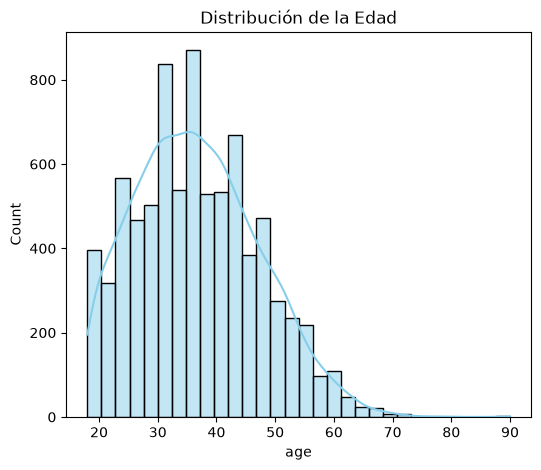

In [20]:
# fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig, ax = plt.subplots(figsize=(6, 5))

# Edad
sns.histplot(df['age'], kde=True, ax=ax, color='skyblue', bins=30)
ax.set_title('Distribución de la Edad')
axes[0].set_xlabel('Edad (años)')
axes[0].set_ylabel('Frecuencia')

plt.show()

Text(0, 0.5, 'Frecuencia')

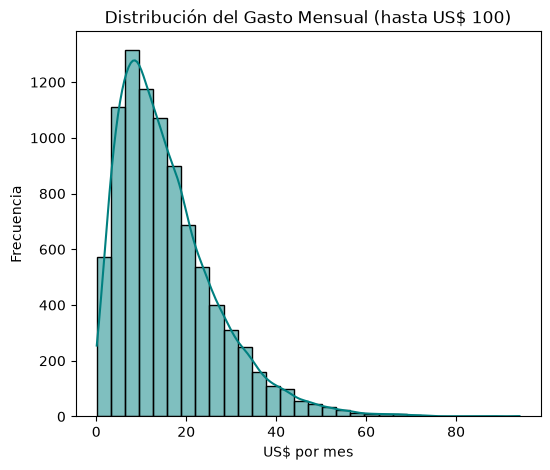

In [23]:
# Gasto mensual (hasta US$ 100)

fig, ax = plt.subplots(figsize=(6, 5))
sns.histplot(df_gasto['monthly_spend'], kde=True, ax=ax, color='teal', bins=30)
ax.set_title('Distribución del Gasto Mensual (hasta US$ 100)')
ax.set_xlabel('US$ por mes')
ax.set_ylabel('Frecuencia')

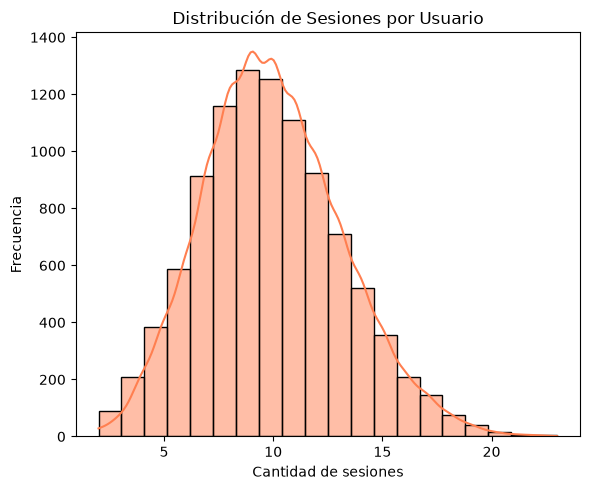

In [24]:


# Sesiones por usuario

fig, ax = plt.subplots(figsize=(6, 5))
sns.histplot(df['n_sesiones'], kde=True, ax=ax, color='coral', bins=20)
ax.set_title('Distribución de Sesiones por Usuario')
ax.set_xlabel('Cantidad de sesiones')
ax.set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

Boxplots (Analizando H2 y H3)

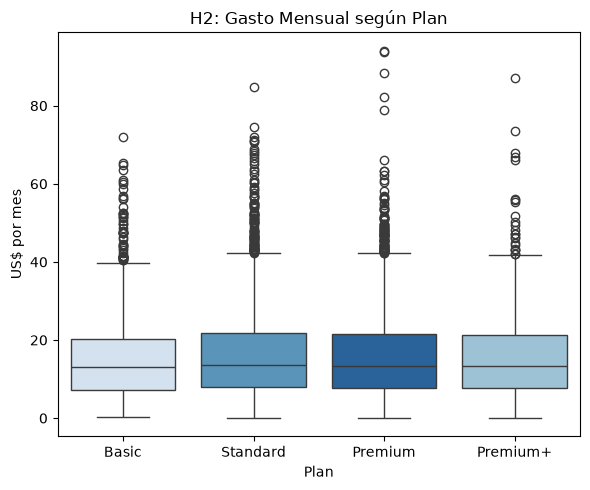

In [34]:
# H2: Gasto mensual según plan

fig, ax = plt.subplots(figsize=(6, 5))
orden_planes = ['Basic', 'Standard', 'Premium', 'Premium+']
sns.boxplot(data=df_gasto, x='subscription_plan', y='monthly_spend', order=orden_planes,
            hue='subscription_plan', legend=False, ax=ax, palette='Blues')
ax.set_title('H2: Gasto Mensual según Plan')
ax.set_xlabel('Plan')
ax.set_ylabel('US$ por mes')


plt.tight_layout()
plt.show()

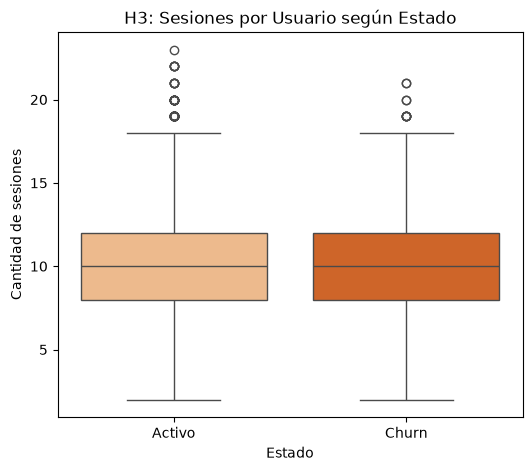

In [33]:
# H3: Sesiones según estado

fig, ax = plt.subplots(figsize=(6, 5))
sns.boxplot(data=df, x='estado', y='n_sesiones', hue='estado', legend=False, ax=ax, palette='Oranges')
ax.set_title('H3: Sesiones por Usuario según Estado')
ax.set_xlabel('Estado')
ax.set_ylabel('Cantidad de sesiones')
plt.show()

Scatterplots (Analizando H3 y H5)

Text(0, 0.5, 'Minutos totales')

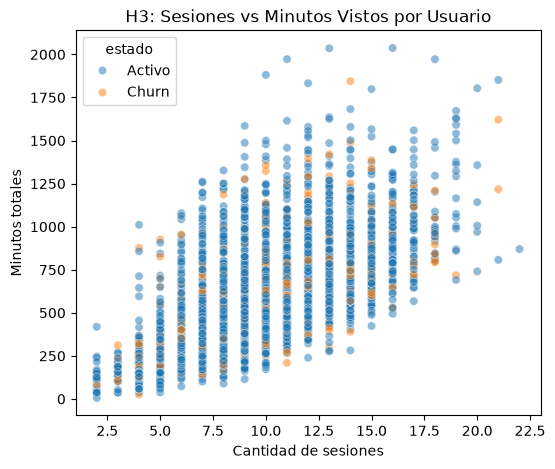

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))

# H3: Sesiones vs minutos vistos, coloreado por estado
sns.scatterplot(data=df.sample(5000, random_state=42), x='n_sesiones', y='minutos_totales',
                hue='estado', alpha=0.5, ax=ax)
ax.set_title('H3: Sesiones vs Minutos Vistos por Usuario')
ax.set_xlabel('Cantidad de sesiones')
ax.set_ylabel('Minutos totales')

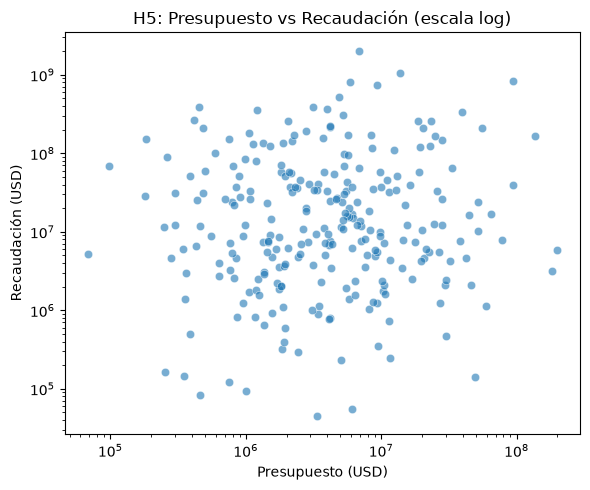

In [40]:
# H5: Presupuesto vs recaudación (escala logarítmica por la gran diferencia de valores)
fig, ax = plt.subplots(figsize=(6, 5))
sns.scatterplot(data=movies, x='production_budget', y='box_office_revenue', alpha=0.6, ax=ax)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title('H5: Presupuesto vs Recaudación (escala log)')
ax.set_xlabel('Presupuesto (USD)')
ax.set_ylabel('Recaudación (USD)')

plt.tight_layout()
plt.show()

Adicionales (Analizando H1, H2 y H4)

En los gráficos de barras de churn, la altura de cada barra es el **promedio de la columna `churn` (0/1)**, es decir, el **porcentaje de usuarios que abandonaron** en cada grupo.

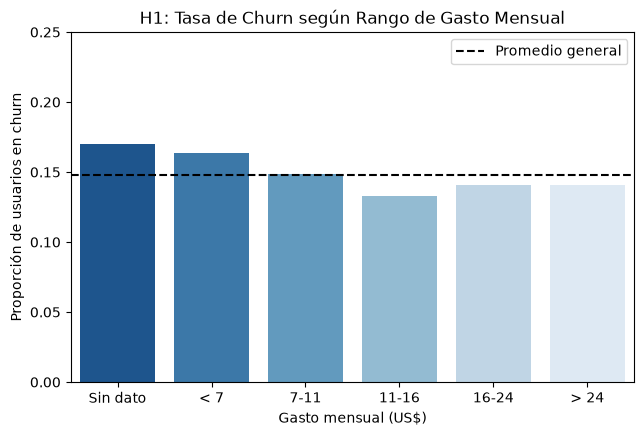

In [53]:
# Rangos de gasto mensual (los usuarios sin dato de gasto forman su propio grupo)
df['rango_gasto'] = pd.cut(df['monthly_spend'], bins=[0, 7, 11, 16, 24, 1000],
                           labels=['< 7', '7-11', '11-16', '16-24', '> 24'])
df['rango_gasto'] = df['rango_gasto'].cat.add_categories('Sin dato').fillna('Sin dato').astype(str)
orden_gasto = ['Sin dato', '< 7', '7-11', '11-16', '16-24', '> 24']

fig = plt.figure(figsize=(16, 10))

# H1 (Insight): Churn según rango de gasto
ax1 = plt.subplot(2, 2, 1)
sns.barplot(data=df, x='rango_gasto', y='churn', order=orden_gasto, errorbar=None,
            hue='rango_gasto', hue_order=orden_gasto, legend=False, palette='Blues_r', ax=ax1)
ax1.axhline(df['churn'].mean(), ls='--', color='black', label='Promedio general')
ax1.set_title('H1: Tasa de Churn según Rango de Gasto Mensual')
ax1.set_xlabel('Gasto mensual (US$)')
ax1.set_ylabel('Proporción de usuarios en churn')
ax1.set_ylim(0, 0.25)
ax1.legend()





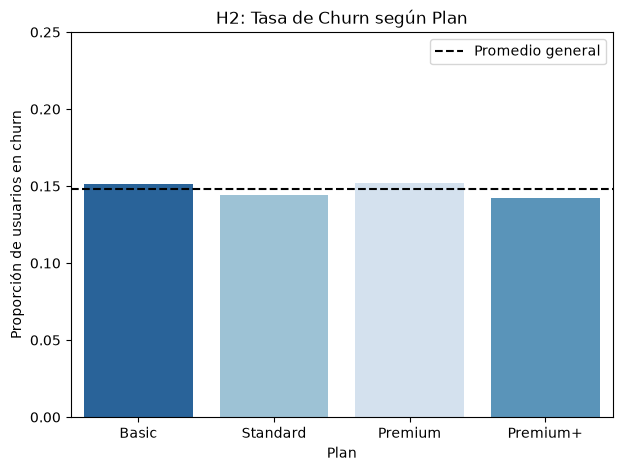

In [54]:
# H2: Churn según plan
fig, ax2 = plt.subplots(figsize=(7, 5))
sns.barplot(data=df, x='subscription_plan', y='churn', order=orden_planes, errorbar=None,
            hue='subscription_plan', legend=False, palette='Blues_r', ax=ax2)
ax2.axhline(df['churn'].mean(), ls='--', color='black', label='Promedio general')
ax2.set_title('H2: Tasa de Churn según Plan')
ax2.set_xlabel('Plan')
ax2.set_ylabel('Proporción de usuarios en churn')
ax2.set_ylim(0, 0.25)
ax2.legend()

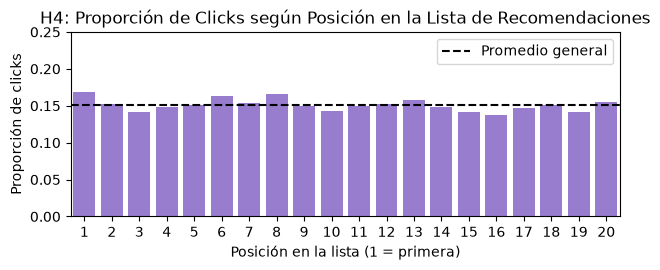

In [45]:
# H4: Clicks según la posición en la lista de recomendaciones
ax3 = plt.subplot(2, 1, 2)
sns.barplot(data=recs, x='position_in_list', y='was_clicked', errorbar=None, color='mediumpurple', ax=ax3)
ax3.axhline(recs['was_clicked'].mean(), ls='--', color='black', label='Promedio general')
ax3.set_title('H4: Proporción de Clicks según Posición en la Lista de Recomendaciones')
ax3.set_xlabel('Posición en la lista (1 = primera)')
ax3.set_ylabel('Proporción de clicks')
ax3.set_ylim(0, 0.25)
ax3.legend()

plt.tight_layout()
plt.show()

In [47]:
# Valores de apoyo para las conclusiones
print('Churn por rango de gasto (%):')
print((df.groupby('rango_gasto')['churn'].mean() * 100).round(1).reindex(orden_gasto))
print()
print('Churn por plan (%):')
print((df.groupby('subscription_plan')['churn'].mean() * 100).round(1))
print()

Churn por rango de gasto (%):
rango_gasto
Sin dato    17.0
< 7         16.4
7-11        14.9
11-16       13.3
16-24       14.0
> 24        14.1
Name: churn, dtype: float64

Churn por plan (%):
subscription_plan
Basic       15.1
Premium     15.2
Premium+    14.2
Standard    14.4
Name: churn, dtype: float64



De los resultados del Análisis Exploratorio de Datos (EDA) sobre el dataset de la plataforma de streaming, podemos establecer respuestas en relación a las hipótesis planteadas:

**Insight: Hipotesis 1: Gasto bajo y churn**
Los usuarios que menos gastan (menos de US$ 7 por mes) y los que no tienen gasto registrado son los que más abandonan: **16,4% y 17,0%** de churn, contra un promedio general de 14,8%. 

**Hipotesis 2 por Plan: Descartada.** El churn es prácticamente igual en todos los planes (entre 14,2% y 15,2%)

**Hipotesis 3 por Consumo: Descartada.** Activos y churn tienen el mismo consumo: 10 sesiones y ≈ 580 minutos promedio, con boxplots prácticamente idénticos. 

**Hipotesis 4 por Recomendaciones: Descartada.** La proporción de clicks es aprox 15% en todas las posiciones 